# HeST Trace Event Viewer

Interactive viewer for traces from `hest_trace_generation.py`. Loads events on demand — no bulk loading.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
import matplotlib.colors as mcolors
import h5py
from pytesdaq.io import H5Reader
%matplotlib inline

/home/dkodroff/miniforge3/envs/pythonstandard/lib/python3.10/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backends is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(
/home/dkodroff/miniforge3/envs/pythonstandard/lib/python3.10/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(


In [5]:
# --- USER CONFIG ---
#TRACE_PATH = '../outputs/continuous_I9_D20261104_T111430/'
TRACE_PATH = '../outputs/continuous_I9_D20261104_T114752/'
HEST_H5_PATH = '../inputs/Spectrum_Mono_ER_energyMin_5900_energyMax_5900_nEvents_10000_seed_42069_HeraldLBNL_TopOnly.h5'
FS = 1.25e6

In [3]:
class EventLoader:
    """Load events on demand with caching. No bulk loading."""

    def __init__(self, trace_path, max_cache=5):
        self.trace_path = trace_path
        self.max_cache = max_cache
        self._cache = {}
        # Count events (read but don't store)
        reader = H5Reader()
        reader.set_files(trace_path)
        self.n_events = 0
        self.n_channels = None
        while True:
            traces, meta = reader.read_next_event(include_metadata=True, adctoamp=False)
            if meta['error_msg'] == 'No more files available':
                break
            if self.n_channels is None:
                self.n_channels = traces.shape[0]
            self.n_events += 1
        reader.close()

    def __len__(self):
        return self.n_events

    def __getitem__(self, idx):
        if idx in self._cache:
            return self._cache[idx]
        reader = H5Reader()
        reader.set_files(self.trace_path)
        for i in range(idx + 1):
            traces, meta = reader.read_next_event(include_metadata=True, adctoamp=True)
            if meta['error_msg'] == 'No more files available':
                reader.close()
                raise IndexError(f'Event {idx} out of range')
        reader.close()
        if len(self._cache) >= self.max_cache:
            del self._cache[min(self._cache)]
        self._cache[idx] = (traces, meta)
        return traces, meta

In [6]:
loader = EventLoader(TRACE_PATH)
n_events = len(loader)
n_channels = loader.n_channels
print(f'{n_events} events, {n_channels} channels (loaded on demand)')

hest_data = None
if HEST_H5_PATH:
    hest_data = h5py.File(HEST_H5_PATH, 'r')
    n_sensors_hest = int(hest_data.attrs['n_sensors'])
    print(f'HeST truth: {hest_data.attrs["n_events"]} events, {n_sensors_hest} sensors')

100 events, 4 channels (loaded on demand)
HeST truth: 10000 events, 4 sensors


In [9]:
def downsample(trace, factor=None):
    """
    Downsample a trace.
    factor=None: no downsampling (full resolution).
    factor=N: take every Nth sample.
    """
    if factor is None or factor <= 1:
        return np.arange(len(trace)), trace
    idx = np.arange(0, len(trace), factor)
    return idx, trace[idx]


def get_hest_truth(event_idx):
    """Get per-sensor energy and recoil info from HeST H5."""
    if hest_data is None:
        return None
    evt_key = str(event_idx)
    if evt_key not in hest_data['events']:
        return None
    evt = hest_data['events'][evt_key]
    sensor_energies = np.zeros(n_channels)
    for ch_key in ['singlet', 'triplet', 'ir', 'qp']:
        if ch_key not in evt:
            continue
        weight = evt[ch_key].attrs.get('weight', 1.0)
        for s in range(n_channels):
            if str(s) in evt[ch_key]:
                sensor_energies[s] += np.sum(evt[ch_key][str(s)]['energies'][:]) * weight
    return {
        'recoil_energy': evt.attrs['recoil_energy'],
        'recoil_type': evt.attrs['recoil_type'],
        'sensor_energies': sensor_energies,
    }

## All channels

In [8]:
def plot_all_channels(event_idx=0, ds_factor=10, xlim=None, ylim=None):
    """
    Plot all channel traces for one event.
    ds_factor: downsample factor (None=full res, 2=every 2nd sample, etc.)
    xlim: (xmin, xmax) in ms, e.g. (4990, 5010). None=full trace.
    ylim: (ymin, ymax) in µA. None=auto.
    """
    traces, _ = loader[event_idx]
    n_ch, n_samp = traces.shape

    truth = get_hest_truth(event_idx)
    title = f'Event {event_idx}'
    if truth:
        title += f' — {truth["recoil_type"]}, E = {truth["recoil_energy"]:.1f} eV'

    ncols = min(4, n_ch)
    nrows = int(np.ceil(n_ch / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), sharex=True, squeeze=False)
    fig.suptitle(title, fontsize=14)

    for ch in range(n_ch):
        ax = axes[ch // ncols, ch % ncols]
        idx, vals = downsample(traces[ch], factor=ds_factor)
        ax.plot(idx / FS * 1e3, vals * 1e6, linewidth=0.3, color='C0')
        ax.set_ylabel(f'ch {ch:02d}', fontsize=8)
        ax.tick_params(labelsize=7)
        if xlim is not None:
            ax.set_xlim(xlim)
        if ylim is not None:
            ax.set_ylim(ylim)

    for i in range(n_ch, nrows * ncols):
        axes[i // ncols, i % ncols].set_visible(False)

    for ax in axes[-1]:
        if ax.get_visible():
            ax.set_xlabel('Time (ms)')
    fig.text(0.04, 0.5, 'Current (µA)', va='center', rotation='vertical', fontsize=12)
    plt.tight_layout(rect=[0.05, 0, 1, 0.97])
    plt.show()


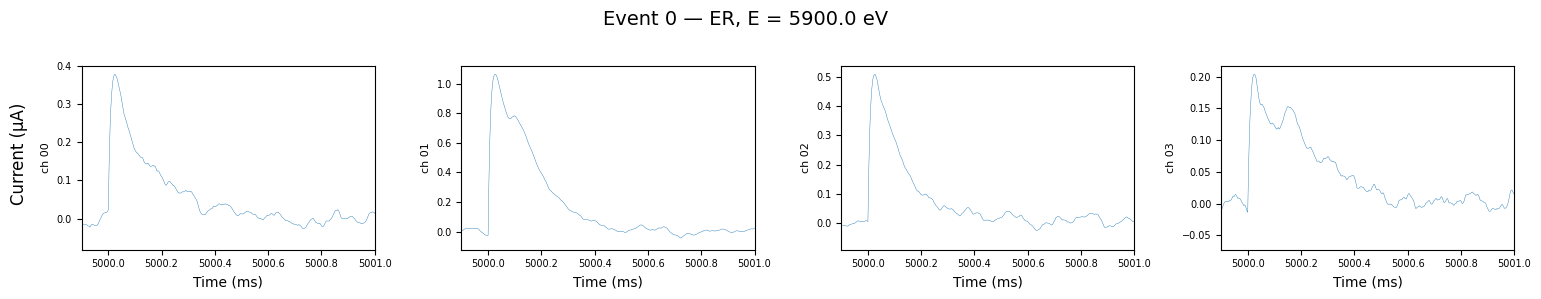

In [14]:
event_idx = 0
plot_all_channels(event_idx, ds_factor=1, xlim=(4999.9,5001))

## Single sensor with truth hits

In [11]:
def plot_sensor_with_truth(event_idx=0, sensor_idx=0, trigger_offset_ms=5000,
                           ds_factor=None, xlim=None, ylim=None):
    """
    Plot one sensor's trace with HeST truth overlay.
    ds_factor: downsample factor (None=full res, 2=every 2nd, etc.)
    xlim: (xmin, xmax) in ms, e.g. (4999, 5005). None=full trace.
    ylim: (ymin, ymax) in µA. None=auto.
    """
    traces, _ = loader[event_idx]
    trace = traces[sensor_idx]
    n_samp = len(trace)

    fig, ax = plt.subplots(figsize=(14, 5))

    idx, vals = downsample(trace, factor=ds_factor)
    ax.plot(idx / FS * 1e3, vals * 1e6, linewidth=0.5, color='C0')

    # Truth overlay
    colors = {'singlet': 'C1', 'triplet': 'C2', 'ir': 'C3', 'qp': 'C4'}
    if hest_data is not None:
        evt_key = str(event_idx)
        if evt_key in hest_data['events']:
            evt = hest_data['events'][evt_key]
            print(f'Event {event_idx}: {evt.attrs["recoil_type"]} recoil, '
                  f'E = {evt.attrs["recoil_energy"]:.2f} eV')
            print(f'Sensor {sensor_idx}:')
            print(f'  {"Channel":<10} {"#hits":>6} {"E_tot (eV)":>11} '
                  f'{"t_mean (µs)":>12} {"t_min (µs)":>11} {"t_max (µs)":>11}')
            print('  ' + '-' * 66)

            for ch_key in ['singlet', 'triplet', 'ir', 'qp']:
                if ch_key not in evt:
                    continue
                ch_grp = evt[ch_key]
                s_key = str(sensor_idx)
                if s_key not in ch_grp:
                    continue
                weight = ch_grp.attrs.get('weight', 1.0)
                times_us = ch_grp[s_key]['arrival_times'][:]
                energies = ch_grp[s_key]['energies'][:] * weight
                n_hits = len(times_us)
                total_e = np.sum(energies)

                print(f'  {ch_key:<10} {n_hits:>6} {total_e:>11.4f} '
                      f'{np.mean(times_us):>12.2f} {np.min(times_us):>11.2f} '
                      f'{np.max(times_us):>11.2f}')

                hit_ms = times_us * 1e-3 + trigger_offset_ms
                for ht in hit_ms[:50]:
                    ax.axvline(ht, color=colors[ch_key], alpha=0.3, lw=0.5)
                ax.axvline(np.nan, color=colors[ch_key], alpha=0.7, lw=1.5,
                           label=f'{ch_key} ({n_hits}, {total_e:.2f} eV)')

    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.set_xlabel('Time (ms)')
    ax.set_ylabel('Current (µA)')
    ax.set_title(f'Event {event_idx} — Sensor {sensor_idx}')
    ax.legend(fontsize=8, loc='upper right')
    plt.tight_layout()
    plt.show()


Event 0: ER recoil, E = 5900.00 eV
Sensor 0:
  Channel     #hits  E_tot (eV)  t_mean (µs)  t_min (µs)  t_max (µs)
  ------------------------------------------------------------------
  singlet         1     16.0000         0.00        0.00        0.00
  ir              9     11.5000         0.00        0.00        0.01
  qp             39      9.3669       217.29      106.44      608.36


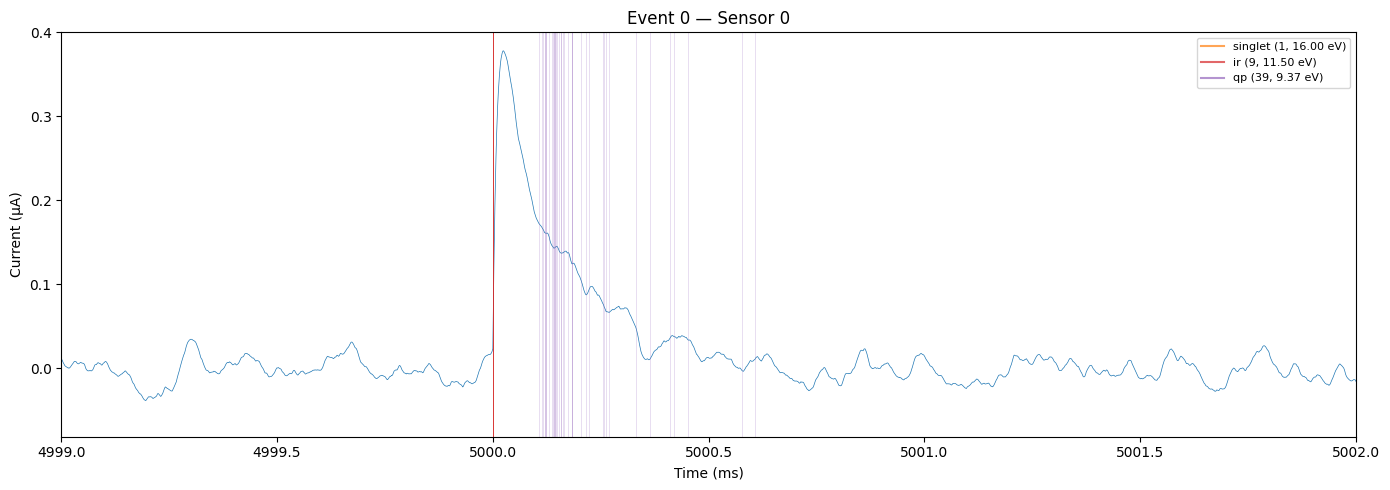

In [ ]:
event_idx = 0
sensor_idx = 0
plot_sensor_with_truth(event_idx, sensor_idx, xlim=(4999, 5002))

## Sensor amplitudes

In [ ]:
def plot_heatmap(event_idx=0, use_truth=False):
    if use_truth:
        truth = get_hest_truth(event_idx)
        if truth is None:
            print('No HeST truth data'); return
        values = truth['sensor_energies']
        label = 'Energy (eV)'
        extra = f' [TRUTH: {truth["recoil_type"]}, E={truth["recoil_energy"]:.1f} eV]'
    else:
        traces, _ = loader[event_idx]
        n_ch = traces.shape[0]
        values = np.zeros(n_ch)
        for i in range(n_ch):
            bl = np.median(traces[i][:len(traces[i])//10])
            values[i] = np.max(np.abs(traces[i] - bl)) * 1e6
        label = 'Amplitude (µA)'
        extra = ''

    n_ch = len(values)
    fig, ax = plt.subplots(figsize=(max(6, n_ch * 0.8), 3))
    vmax = max(np.max(values), 1e-12)

    bar_colors = plt.cm.inferno(values / vmax)
    ax.bar(range(n_ch), values, color=bar_colors, edgecolor='gray', linewidth=0.5)
    ax.set_xticks(range(n_ch))
    ax.set_xticklabels([f'{i}' for i in range(n_ch)])
    ax.set_xlabel('Sensor')
    ax.set_ylabel(label)
    ax.set_title(f'Event {event_idx}{extra}')
    plt.tight_layout(); plt.show()


plot_heatmap(0, use_truth=False)